# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Maribao, Jake Agustin
- _Student No._: 2023-08777
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

**Problem 1.** Gaussian wave packet (top), unit-area Gaussians narrowing toward a Dirac delta (middle) and the Dirac delta itself (bottom).

<img src="p1_packet_signal.png" alt="p1_packet_signal" width=32%> <img src="p1_packet_magnitude.png" alt="p1_packet_magnitude" width=32%> <img src="p1_packet_phase.png" alt="p1_packet_phase" width=32%>
<img src="p1_nascent_signal.png" alt="p1_nascent_signal" width=32%> <img src="p1_nascent_magnitude.png" alt="p1_nascent_magnitude" width=32%> <img src="p1_nascent_phase.png" alt="p1_nascent_phase" width=32%>
<img src="p1_delta_signal.png" alt="p1_delta_signal" width=32%> <img src="p1_delta_magnitude.png" alt="p1_delta_magnitude" width=32%> <img src="p1_delta_phase.png" alt="p1_delta_phase" width=32%>

_Figure 1. Signal (left), magnitude of the Fourier transform (middle) and wrapped phase (right). A longer wave packet gives narrower peaks at ±5 Hz. A narrower unit-area Gaussian gives a wider transform, and the delta's transform is flat at 1 for every frequency. The phase is hidden where |F| is below 0.1% of its maximum._

**Problem 2.** Noise filtering in Fourier space.

<img src="p2_threshold.png" alt="p2_threshold" width=48%> <img src="p2_recovered.png" alt="p2_recovered" width=48%>
<img src="p2_error_vs_N.png" alt="p2_error_vs_N" width=48%>

_Figure 2. Left: FT of the noisy, Hann-windowed signal (N = 25000) with the threshold at 65% of the tallest peak, which keeps only the bins at ±130, ±180 and ±230 Hz. Right: the recovered signal over the first 0.3 s lies on the original, with an RMS error of 0.089 against a signal RMS of 1.225. Bottom: median recovery error over 30 noise draws as N decreases._

**Problem 3.** Aliasing of a 1000 Hz sine.

<img src="p3_time_good.png" alt="p3_time_good" width=32%> <img src="p3_time_alias.png" alt="p3_time_alias" width=32%> <img src="p3_fft.png" alt="p3_fft" width=32%>

_Figure 3. Left: sampled at 2500 Hz, above the Nyquist rate, the samples follow the 1000 Hz signal. Middle: sampled at 1100 Hz, below the Nyquist rate, the samples trace a 100 Hz wave (dashed). Right: the FT has peaks at ±1000 Hz for the first rate and at ±100 Hz for the aliased one._

### Report discussion

**Problem 1.** For the Gaussian wave packet, a wider envelope gives narrower peaks at ±5 Hz. Their full width at half maximum fell from 1.85 Hz to 0.70 Hz to 0.35 Hz as σ grew from 0.2 s to 0.5 s to 1 s, so a longer packet has a better defined frequency. Squeezing a unit-area Gaussian toward a Dirac delta does the opposite, keeping its transform at height 1 at f = 0 while the width grows from 3.7 Hz to 37 Hz, until the ideal delta has a flat transform equal to 1 at every frequency. All of these signals are real and even about t = 0, so their phase is zero wherever the magnitude is not negligible.

**Problem 2.** Lowering N with dt fixed shortens the record (N = 5000 covers 1 s instead of 5 s), so the clean signal looks the same but its FT peaks become shorter and wider because the frequency resolution 1/(N dt) gets coarser. The tones add coherently, so their peaks grow in proportion to N, while the random noise grows only as √N, so the peaks sink toward the noise floor as N shrinks and noise bins start passing the threshold. Over 30 noise draws, the median recovery error was 14% of the signal's RMS at N = 25000, 22% at 15000, 57% at 10000 and 178% at 5000, so with this noise (standard deviation 10) the signal is recovered well only for N of roughly 15000 or more, and the limit would drop for weaker noise.

**Problem 3.** Figure 3 uses a 1000 Hz sine sampled for 10 s, so the Nyquist rate is 2000 Hz. Sampled at 2500 Hz, above the Nyquist rate, the samples follow the true signal and the FT has two peaks at ±1000 Hz. Sampled at 1100 Hz, below it, the samples trace a 100 Hz wave instead and the FT peaks move to ±100 Hz, because the 1000 Hz component folds to 1000 - 1100 = -100 Hz. The two transforms are therefore not the same even though they come from the same signal. A sampling rate that divides 1000 Hz exactly, such as 10 or 100 Hz, would be a poor choice, since every sample would land on a zero crossing and the signal would vanish.

### Other comments
- The noise generator in Problem 2 is seeded with `default_rng(0)`, so the numbers quoted above are reproducible.
- Dividing the recovered signal by `window.mean()` undoes the factor of 0.5 that the Hann window puts on every peak. Without it, the recovered signal has half the original amplitude.
- The phase helper from Problem 1 is named `ft_phase` because the Problem 2 template already uses `phase` for its list of phase shifts.
- Reflection: the Hann window spreads each tone over three bins, with the side bins at half height, so the threshold had to clear those side bins as well as the noise. That made choosing it harder than I expected.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

**Approach.** Every waveform is sampled on one symmetric grid (dt = 0.005 s over 40 s) and transformed with `ft()`, which approximates the continuous Fourier transform.
- `np.fft.ifftshift` moves t = 0 to the first sample before the FFT, so the phase is measured relative to t = 0 instead of the start of the window.
- Multiplying by `dt` turns the FFT sum into an approximation of the integral, so the peak heights of different signals can be compared.
- `ft_phase()` hides the phase wherever |F| is below 0.1% of its maximum, because the angle of a near-zero number is only rounding noise.
- `plot_ft()` overlays the variations of one waveform and draws the signal, magnitude and phase as three separate figures.

In [2]:
dt = 0.005                          # sampling step (s)
T = 40                              # total window (s), long so every signal decays or repeats whole periods
N = int(T/dt)
t = (np.arange(N) - N//2)*dt        # symmetric grid with t = 0 at index N//2
f = np.fft.fftshift(np.fft.fftfreq(N, dt))

def ft(y):
    """Approximate the continuous Fourier transform F(f) of y(t)."""
    return np.fft.fftshift(np.fft.fft(np.fft.ifftshift(y)))*dt   # ifftshift moves t = 0 to index 0, so the phase is measured relative to t = 0

def ft_phase(F, tol=1e-3):
    """Wrapped phase, hidden where |F| is too small for the phase to mean anything."""
    p = np.angle(F)
    p[p < -np.pi + 0.01] += 2*np.pi                 # -pi and +pi are the same angle, show both as +pi
    p[np.abs(F) < tol*np.abs(F).max()] = np.nan
    return p

def plot_ft(signals, title, tlim, flim, save=None):
    """Three separate figures: signal, |F(f)| and phase for every variation in the dict signals.
    If save is given, the figures are also saved as save_signal.png, save_magnitude.png and save_phase.png."""
    figs = [plt.subplots(figsize=(8, 4)) for _ in range(3)]
    ax = [a for _, a in figs]
    for i, (label, y) in enumerate(signals.items()):
        F = ft(y)
        style = dict(color=f'C{i}', zorder=-i, label=label)
        ax[0].plot(t, y, lw=1 + 0.8*i, **style)
        ax[1].plot(f, np.abs(F), lw=1 + 0.8*i, **style)
        ax[2].plot(f, ft_phase(F), '.', ms=3 + 2*i, **style)
    ax[0].set(xlim=tlim, xlabel='t (s)', ylabel='y(t)', title=f'{title}: signal')
    ax[1].set(xlim=flim, xlabel='f (Hz)', ylabel='|F(f)|', title=f'{title}: magnitude of FT')
    ax[2].set(xlim=flim, ylim=(-3.5, 3.5), xlabel='f (Hz)', ylabel='phase (rad)', title=f'{title}: phase of FT')
    ax[2].set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi], ['-π', '-π/2', '0', 'π/2', 'π'])
    for a in ax:
        a.legend(loc='upper center', ncol=3, fontsize=8)
    for (fig, _), name in zip(figs, ('signal', 'magnitude', 'phase')):
        fig.tight_layout()
        if save:
            fig.savefig(f'{save}_{name}.png', dpi=120)
    plt.show()

#### Gaussian wave packet (5 Hz cosine under a Gaussian envelope, vary σ)

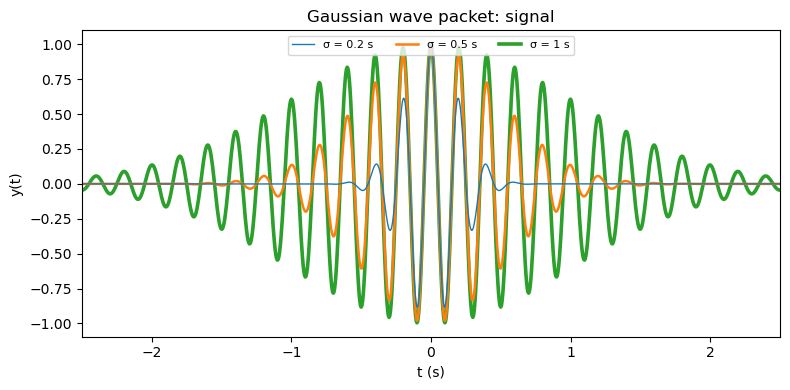

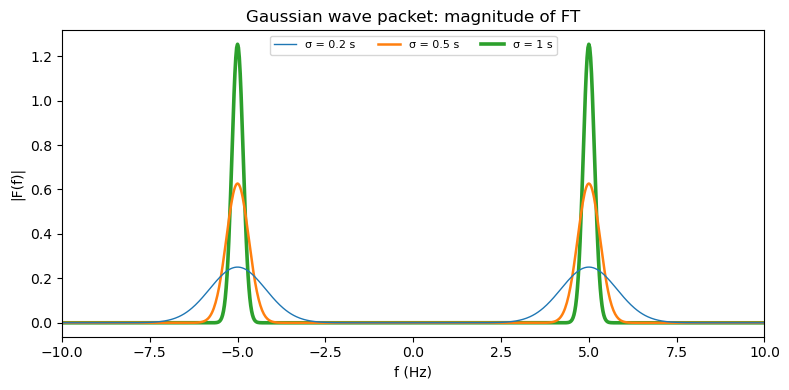

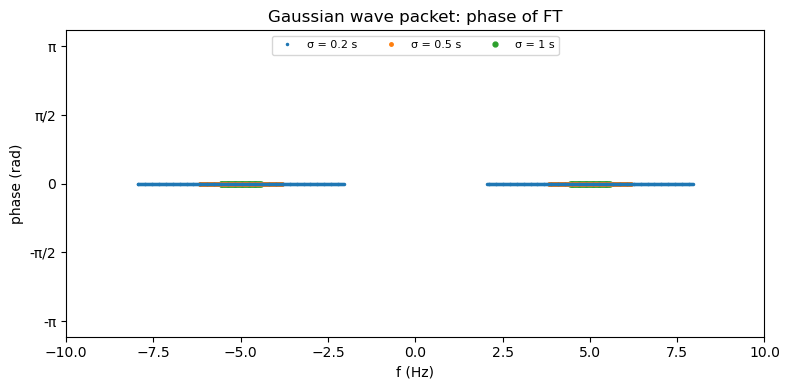

In [3]:
f0 = 5
packets = {f'σ = {s} s': np.exp(-t**2/(2*s**2))*np.cos(2*np.pi*f0*t) for s in (0.2, 0.5, 1)}
plot_ft(packets, 'Gaussian wave packet', tlim=(-2.5, 2.5), flim=(-10, 10), save='p1_packet')

#### Dirac delta (unit-area Gaussians narrowing toward δ(t), then δ(t) itself)

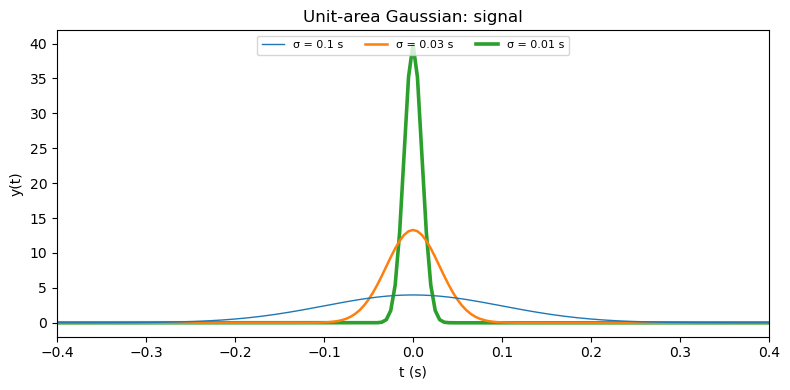

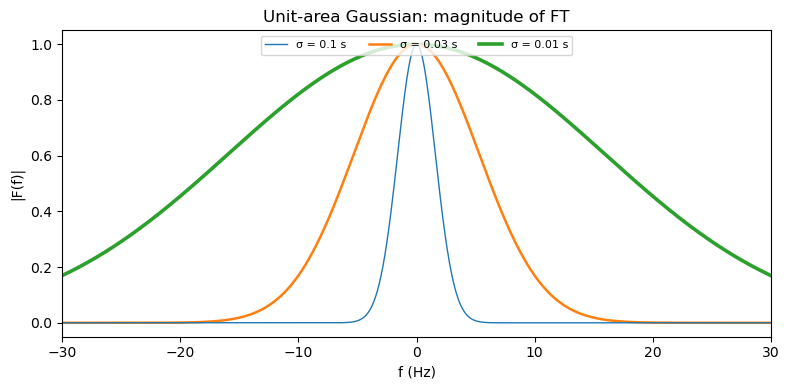

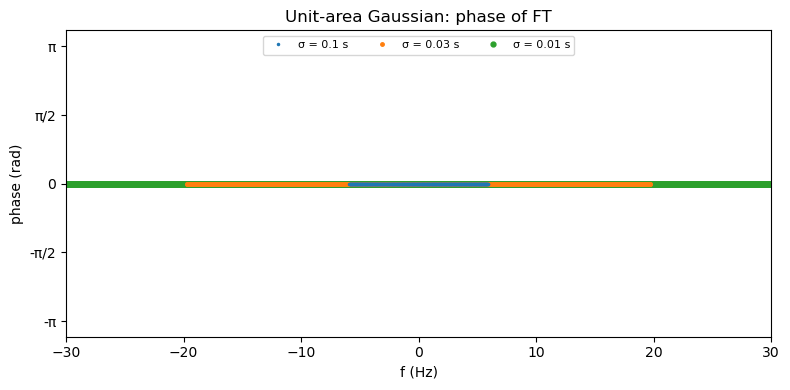

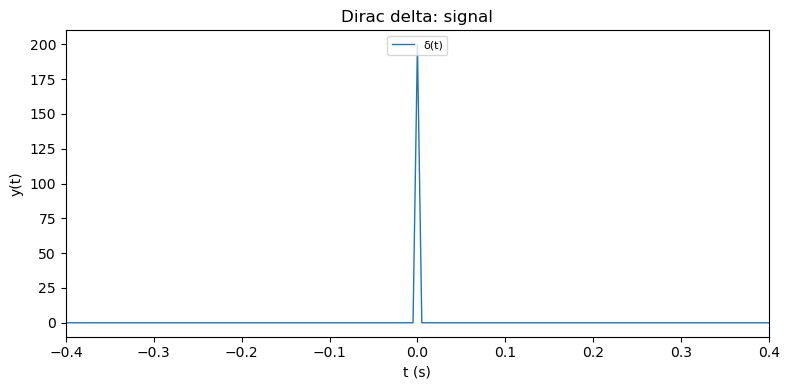

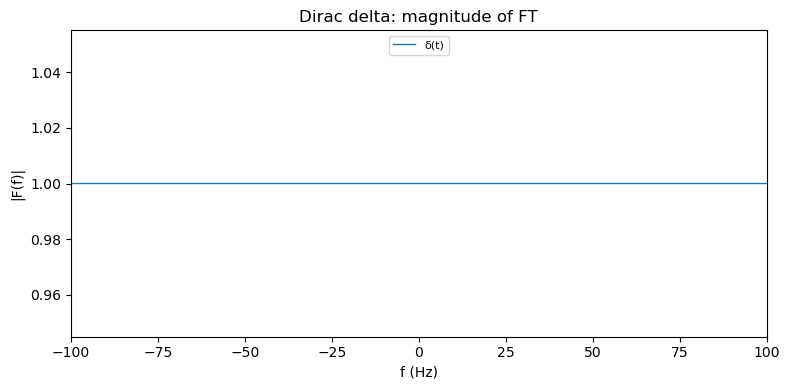

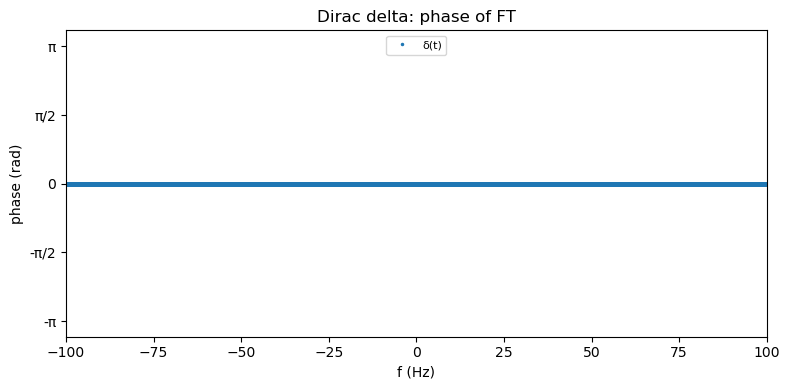

In [4]:
# Nascent deltas: Gaussians with area 1, so they grow taller as they get narrower
nascent = {f'σ = {s} s': np.exp(-t**2/(2*s**2))/(s*np.sqrt(2*np.pi)) for s in (0.1, 0.03, 0.01)}
plot_ft(nascent, 'Unit-area Gaussian', tlim=(-0.4, 0.4), flim=(-30, 30), save='p1_nascent')

# The delta on a grid: one sample at t = 0 with height 1/dt, so the area is exactly 1
delta = np.zeros(N)
delta[N//2] = 1/dt
plot_ft({'δ(t)': delta}, 'Dirac delta', tlim=(-0.4, 0.4), flim=(-100, 100), save='p1_delta')

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


**Approach.** The steps follow the template order. The FFT of the noisy data is taken after multiplying it by a Hann window. The threshold is set at 65% of the tallest peak, high enough to reject both the noise and the half-height side bins that the window creates around each tone. The kept bins are transformed back with `np.fft.ifft` and divided by `window.mean()` to undo the 0.5 amplitude factor of the window, and the result is compared with the clean signal through its RMS error.

In [5]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

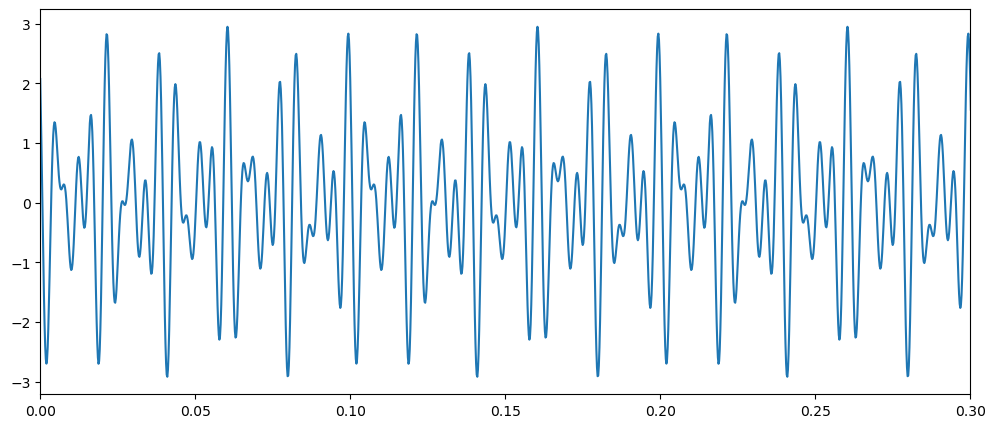

In [6]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

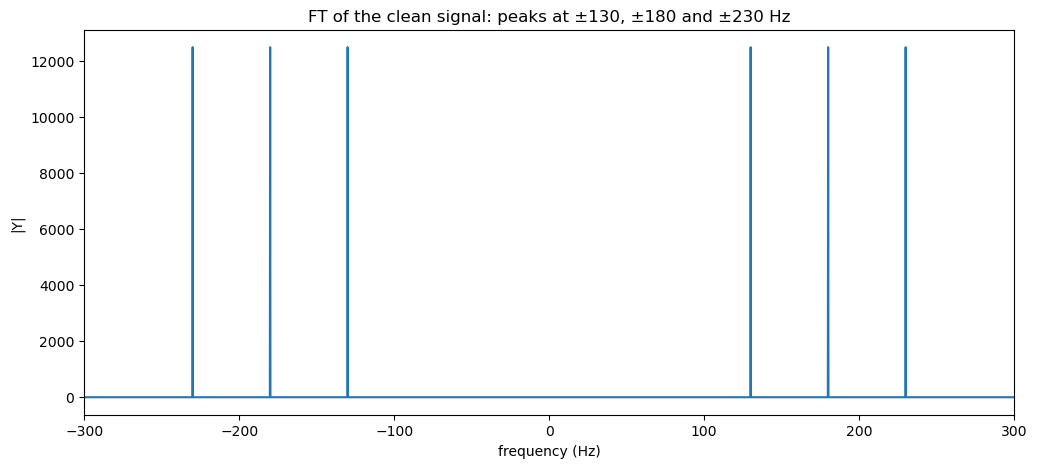

In [7]:
#FILL: Plot the fourier transform of the clean, original signal
cleanFourier = np.fft.fft(signal_original)
sigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(sigFreqs, np.abs(np.fft.fftshift(cleanFourier)))
ax.set_xlim(-300, 300)
ax.set(xlabel='frequency (Hz)', ylabel='|Y|', title='FT of the clean signal: peaks at ±130, ±180 and ±230 Hz')
plt.show()

In [8]:
rng = np.random.default_rng(0)   # seeded so the results quoted in the discussion are reproducible

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

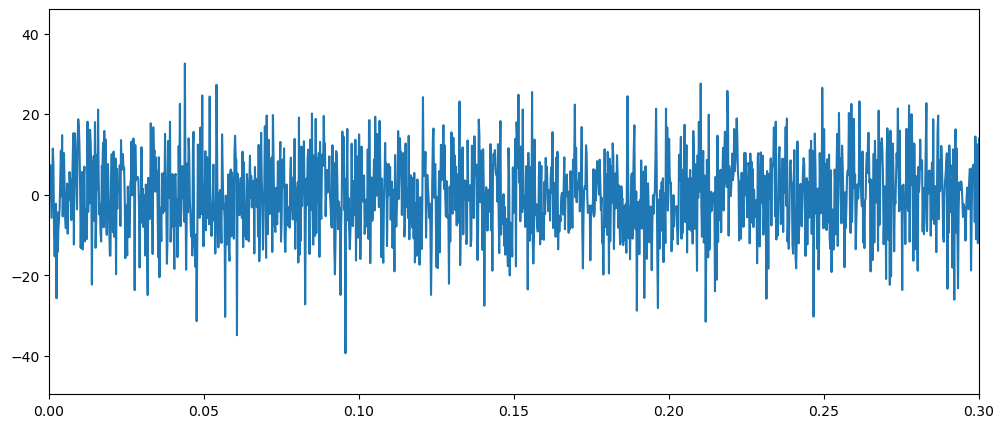

In [9]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

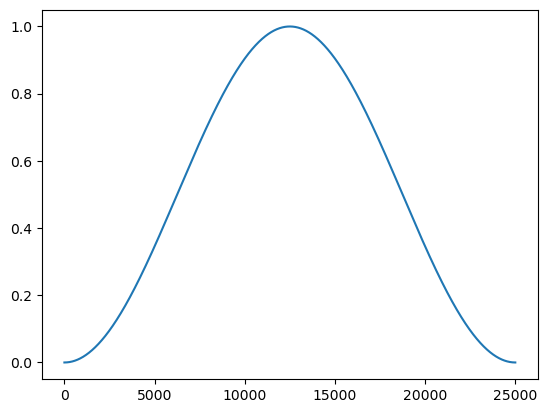

In [10]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [11]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


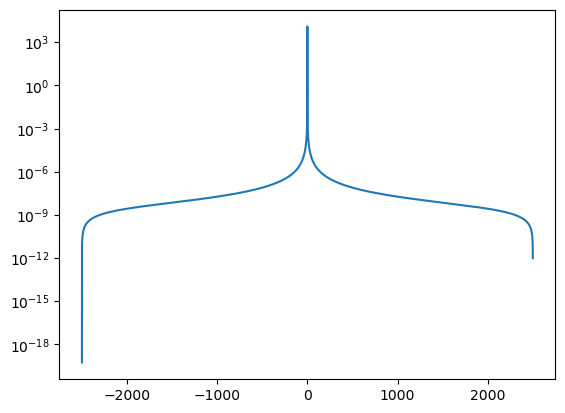

In [12]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [13]:
noisyFourier = np.fft.fft(noisy_data*window)

# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


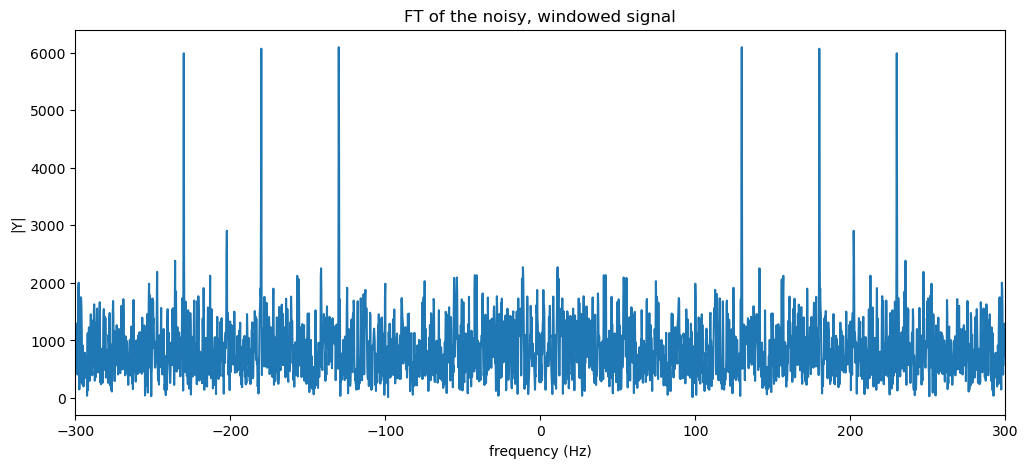

In [14]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window
noisySigPeaks = np.abs(np.fft.fftshift(noisyFourier))

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(sigFreqs, noisySigPeaks)
ax.set_xlim(-300, 300)
ax.set(xlabel='frequency (Hz)', ylabel='|Y|', title='FT of the noisy, windowed signal')
plt.show()

threshold = 3961, kept frequencies (Hz): [ 130.  180.  230. -230. -180. -130.]


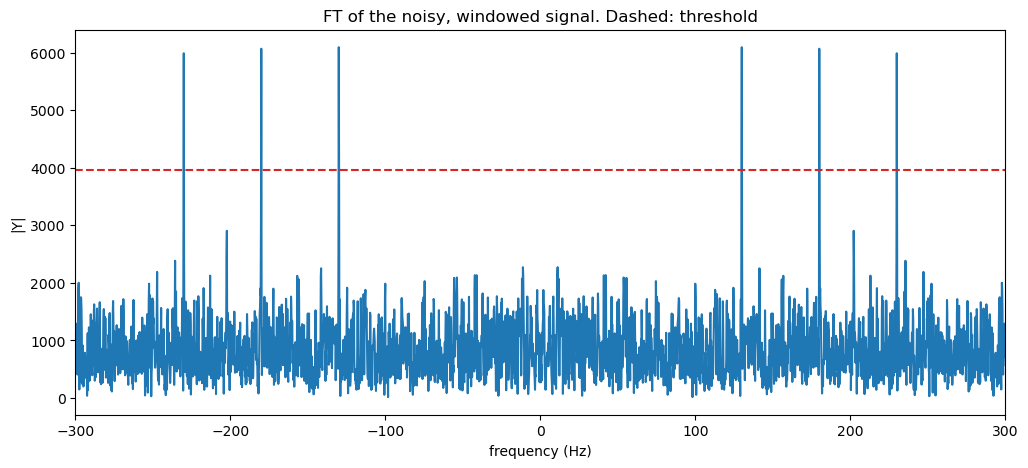

In [15]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
# The Hann window spreads each tone over 3 bins, and the two side bins are half as tall as the centre bin.
# 65% of the tallest peak sits above both the side bins and the noise floor, so one bin per tone survives.
threshold = 0.65*np.abs(noisyFourier).max()
keep = np.abs(noisyFourier) > threshold
print(f'threshold = {threshold:.0f}, kept frequencies (Hz): {np.fft.fftfreq(N, dt)[keep]}')

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(sigFreqs, noisySigPeaks)
ax.axhline(threshold, color='C3', ls='--')
ax.set_xlim(-300, 300)
ax.set(xlabel='frequency (Hz)', ylabel='|Y|', title='FT of the noisy, windowed signal. Dashed: threshold')
fig.savefig('p2_threshold.png', dpi=120)
plt.show()

In [16]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain
cleanedFourier = np.where(keep, noisyFourier, 0)               # zero every bin below the threshold
# The Hann window scales each peak by its mean value (0.5), so dividing by window.mean() restores the amplitudes
recoveredSignal = np.fft.ifft(cleanedFourier).real / window.mean()

RMS error over the full 5 s: 0.089 (the clean signal has an RMS of 1.225)


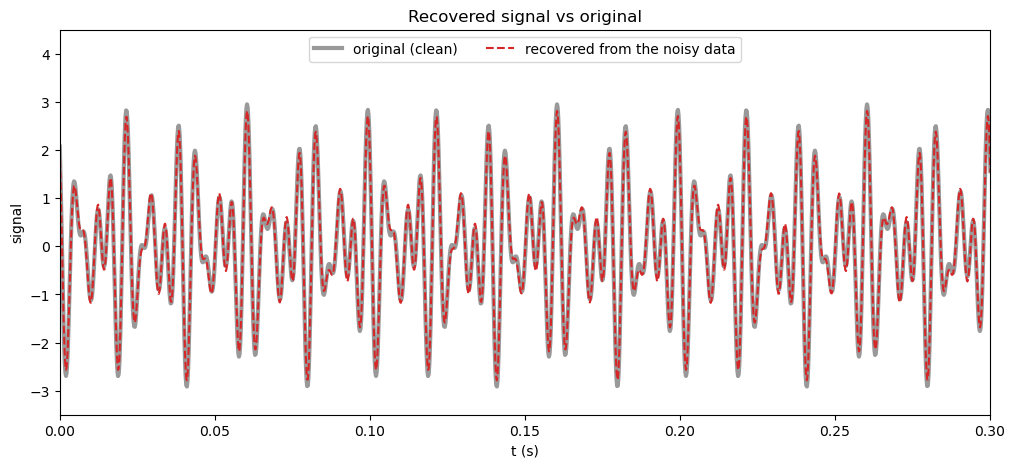

In [17]:
# Plot the recovered signal
rmse = np.sqrt(np.mean((recoveredSignal - signal_original)**2))
print(f'RMS error over the full {N*dt:.0f} s: {rmse:.3f} (the clean signal has an RMS of {np.sqrt(np.mean(signal_original**2)):.3f})')

fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original, color='0.6', lw=3, label='original (clean)')
ax.plot(t_, recoveredSignal, 'C3--', label='recovered from the noisy data')
ax.set_xlim(0,0.3)
ax.set(ylim=(-3.5, 4.5), xlabel='t (s)', ylabel='signal', title='Recovered signal vs original')
ax.legend(loc='upper center', ncol=2)
fig.savefig('p2_recovered.png', dpi=120)
plt.show()

#### Effect of N
`recovery_error()` repeats the whole procedure for a given N with the same dt, frequencies and noise, and returns the RMS error divided by the RMS of the clean signal. The median over 30 noise draws is used so that one lucky or unlucky draw does not decide the trend.

N =   500  (0.1 s)   relative error = 5.46
N =  1000  (0.2 s)   relative error = 4.96
N =  2000  (0.4 s)   relative error = 3.83
N =  5000  (1.0 s)   relative error = 1.78
N =  7500  (1.5 s)   relative error = 0.94
N = 10000  (2.0 s)   relative error = 0.57
N = 15000  (3.0 s)   relative error = 0.22
N = 20000  (4.0 s)   relative error = 0.16
N = 25000  (5.0 s)   relative error = 0.14


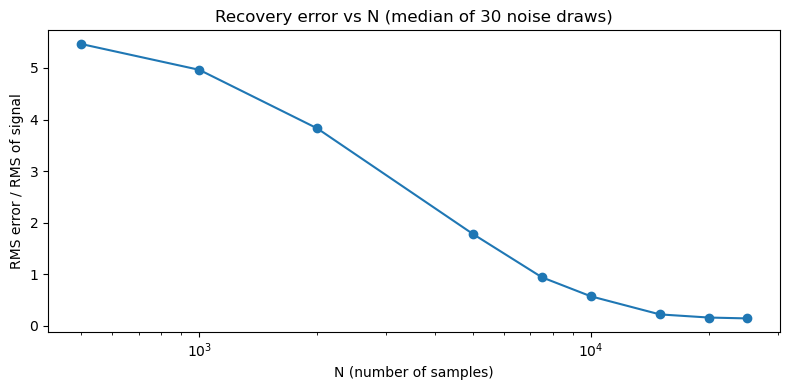

In [18]:
def recovery_error(n, seed):
    """Repeat the whole procedure with n samples and return the RMS error relative to the clean signal's RMS."""
    t_n = np.arange(n)*dt
    clean = np.sum([np.cos(2*np.pi*f*t_n + p) for f, p in zip(freqs, phase)], axis=0)
    noisy = clean + np.random.default_rng(seed).normal(mean, std, n)*5
    w = np.hanning(n)
    F = np.fft.fft(noisy*w)
    F[np.abs(F) <= 0.65*np.abs(F).max()] = 0
    rec = np.fft.ifft(F).real / w.mean()
    return np.sqrt(np.mean((rec - clean)**2)) / np.sqrt(np.mean(clean**2))

Ns = [500, 1000, 2000, 5000, 7500, 10000, 15000, 20000, 25000]
errors = [np.median([recovery_error(n, s) for s in range(30)]) for n in Ns]   # median over 30 noise draws
for n, e in zip(Ns, errors):
    print(f'N = {n:5d}  ({n*dt:.1f} s)   relative error = {e:.2f}')

fig, ax = plt.subplots(figsize=(8,4))
ax.semilogx(Ns, errors, 'o-')
ax.set(xlabel='N (number of samples)', ylabel='RMS error / RMS of signal', title='Recovery error vs N (median of 30 noise draws)')
fig.tight_layout()
fig.savefig('p2_error_vs_N.png', dpi=120)
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

**Approach.** A 1000 Hz sine is sampled for 10 s at 2500 Hz, above the Nyquist rate of 2000 Hz, and at 1100 Hz, below it. Each FFT is divided by its number of samples so that both spectra have the same peak height and can share one plot. A fine time grid stands in for the continuous signal, and the dashed curve is the alias at `f_sig - fs_alias` = -100 Hz.

In [19]:
f_sig = 1000          # signal frequency (Hz), so the Nyquist rate is 2*f_sig = 2000 Hz
T_sig = 10            # sampling time (s), a whole number of cycles at both rates below
fs_good = 2500        # above the Nyquist rate: not aliased
fs_alias = 1100       # below the Nyquist rate: aliased

def sample(fs):
    """Sample the sine at rate fs and return the sample times, values, FFT frequencies and normalized |FFT|."""
    tn = np.arange(0, T_sig, 1/fs)
    yn = np.sin(2*np.pi*f_sig*tn)
    Yn = np.fft.fftshift(np.abs(np.fft.fft(yn)))/len(yn)   # dividing by the number of samples makes both peaks 0.5 tall
    fn = np.fft.fftshift(np.fft.fftfreq(len(yn), 1/fs))
    return tn, yn, fn, Yn

t_good, y_good, f_good, Y_good = sample(fs_good)
t_alias, y_alias, f_alias, Y_alias = sample(fs_alias)
print(f'fs = {fs_good} Hz: strongest frequency = {abs(f_good[Y_good.argmax()]):.0f} Hz')
print(f'fs = {fs_alias} Hz: strongest frequency = {abs(f_alias[Y_alias.argmax()]):.0f} Hz')

fs = 2500 Hz: strongest frequency = 1000 Hz
fs = 1100 Hz: strongest frequency = 100 Hz


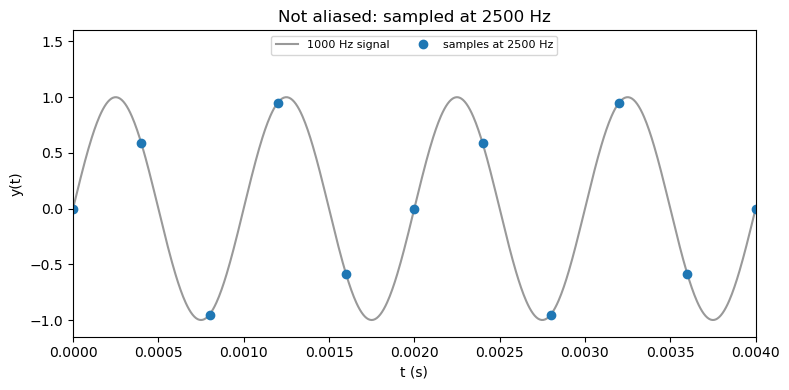

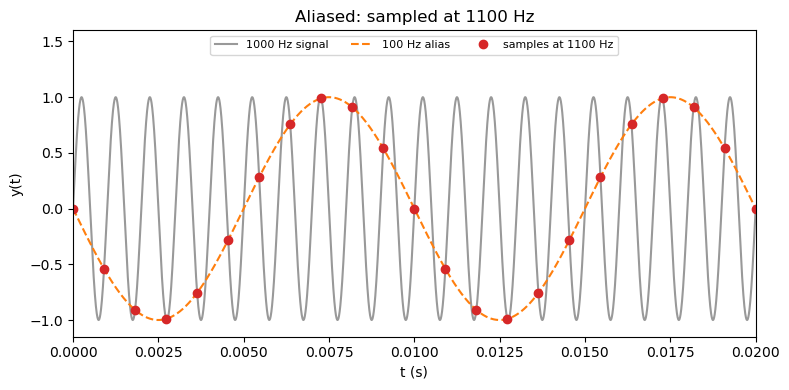

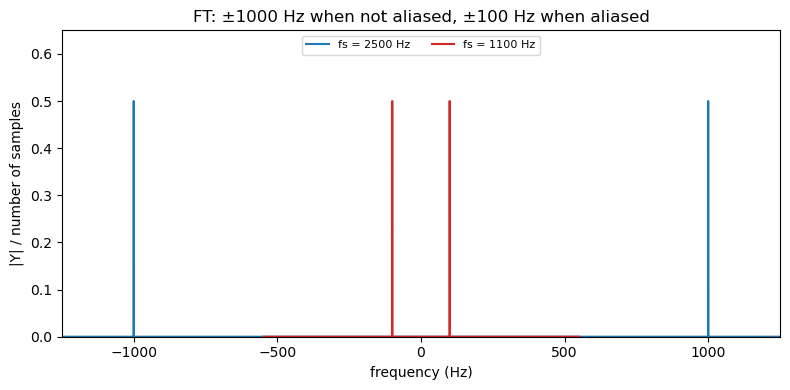

In [20]:
t_dense = np.linspace(0, 0.02, 4000)          # fine grid that stands in for the continuous signal

# Actual signal, sampled above the Nyquist rate
fig, ax = plt.subplots(figsize=(8,4))
show = t_good <= 0.004
ax.plot(t_dense, np.sin(2*np.pi*f_sig*t_dense), color='0.6', label='1000 Hz signal')
ax.plot(t_good[show], y_good[show], 'o', color='C0', label=f'samples at {fs_good} Hz')
ax.set(xlim=(0, 0.004), ylim=(-1.15, 1.6), xlabel='t (s)', ylabel='y(t)', title=f'Not aliased: sampled at {fs_good} Hz')
ax.legend(loc='upper center', ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig('p3_time_good.png', dpi=120)
plt.show()

# Aliased signal, sampled below the Nyquist rate
fig, ax = plt.subplots(figsize=(8,4))
show = t_alias <= 0.02
ax.plot(t_dense, np.sin(2*np.pi*f_sig*t_dense), color='0.6', label='1000 Hz signal')
ax.plot(t_dense, np.sin(2*np.pi*(f_sig - fs_alias)*t_dense), 'C1--', label='100 Hz alias')
ax.plot(t_alias[show], y_alias[show], 'o', color='C3', label=f'samples at {fs_alias} Hz')
ax.set(xlim=(0, 0.02), ylim=(-1.15, 1.6), xlabel='t (s)', ylabel='y(t)', title=f'Aliased: sampled at {fs_alias} Hz')
ax.legend(loc='upper center', ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig('p3_time_alias.png', dpi=120)
plt.show()

# Fourier transforms of both
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(f_good, Y_good, color='C0', label=f'fs = {fs_good} Hz')
ax.plot(f_alias, Y_alias, color='C3', label=f'fs = {fs_alias} Hz')
ax.set(xlim=(-1250, 1250), xlabel='frequency (Hz)', ylabel='|Y| / number of samples', ylim=(0, 0.65), title='FT: ±1000 Hz when not aliased, ±100 Hz when aliased')
ax.legend(loc='upper center', ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig('p3_fft.png', dpi=120)
plt.show()

#### Problem code summary

This notebook shows how the shape of a signal sets its Fourier transform, how thresholding in Fourier space removes noise, and how sampling below the Nyquist rate aliases a signal. A single helper, `ft()`, combines `np.fft.fft` with an `ifftshift` and a factor of `dt` so that every Problem 1 waveform has a comparable magnitude and a phase measured from t = 0. In Problems 2 and 3, the threshold, the `window.mean()` rescaling and the normalization by the number of samples all follow from how the window and the sample count change the height of a spectral peak.

---
## Section 3: Notes

In [21]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

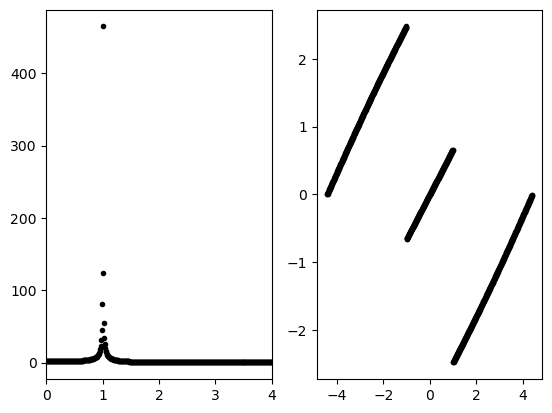

In [22]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [23]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

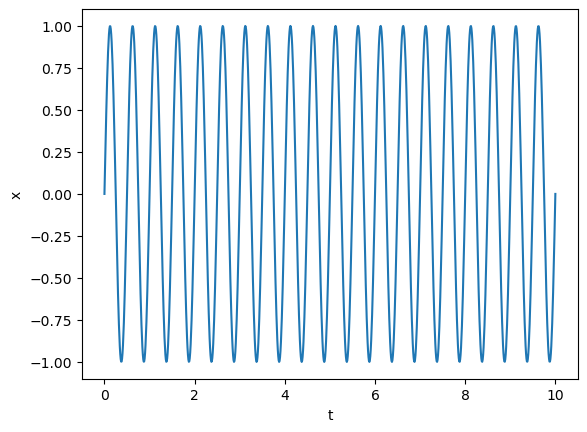

In [24]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [25]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

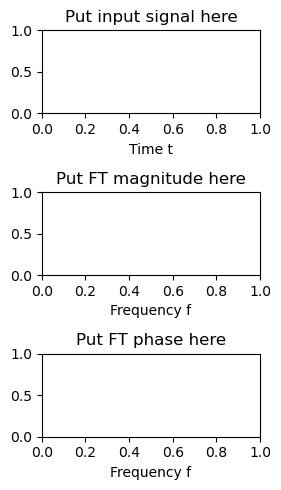

In [26]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

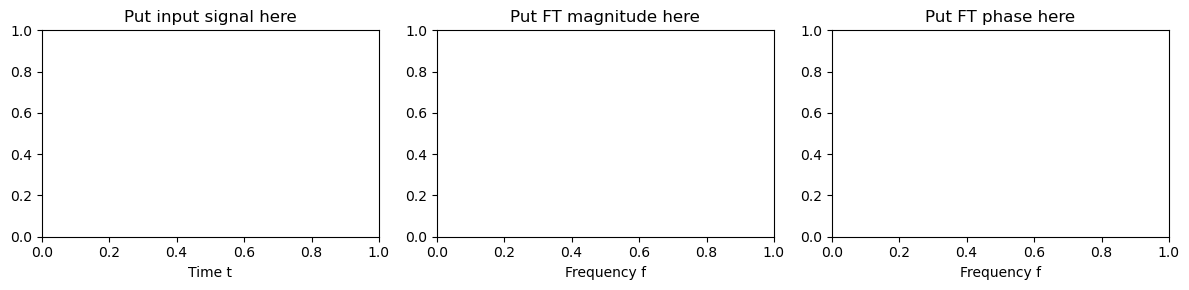

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

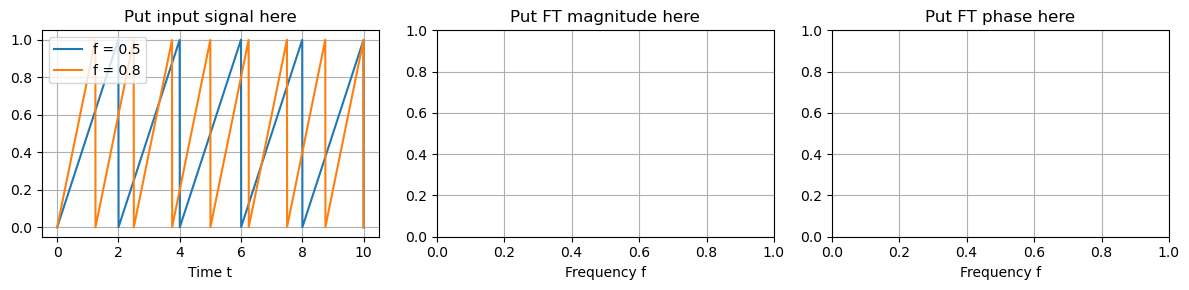

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [29]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



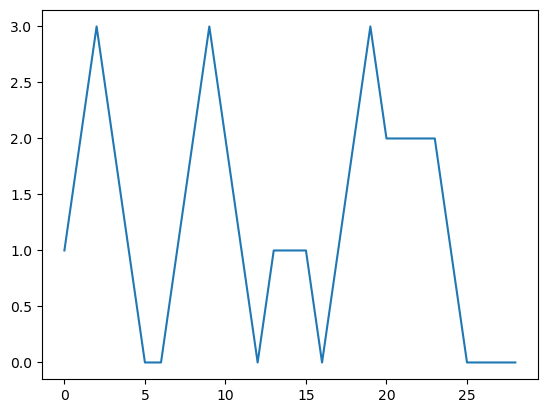

In [30]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [31]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [32]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

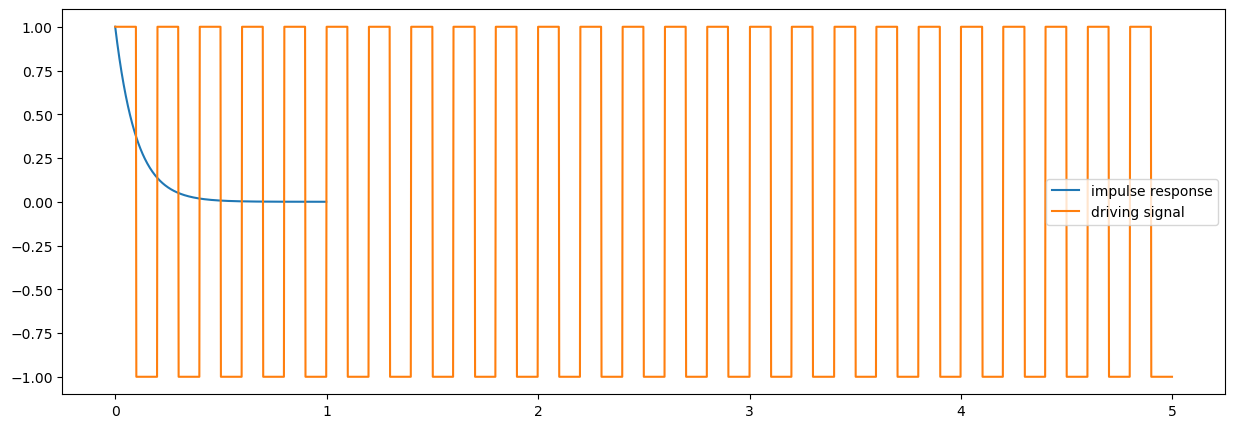

In [33]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [34]:
response = np.convolve(input_signal, h_t, mode = "same")

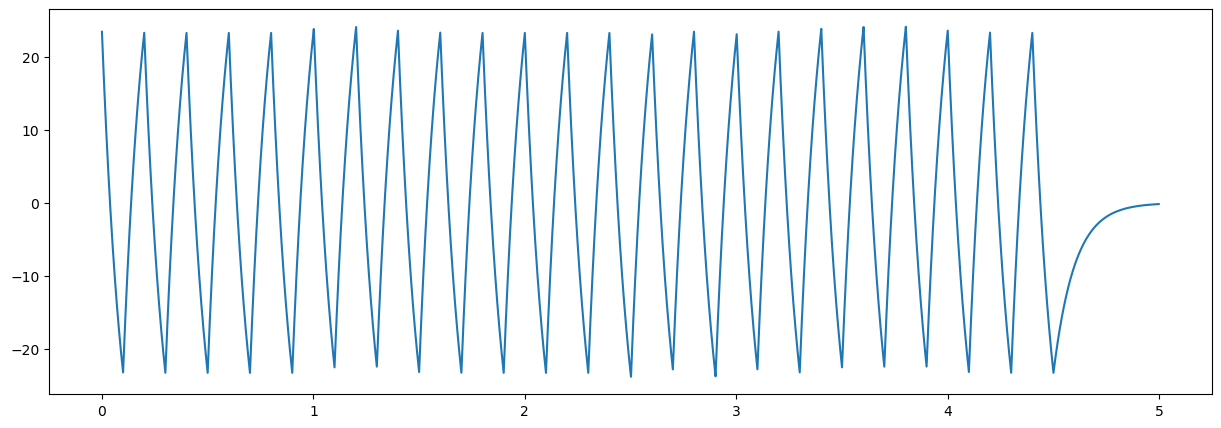

In [35]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [36]:
fourier_length = len(h_t) + len(input_signal) - 1

In [37]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [38]:
fourier_response = fourier_h*fourier_input 

In [39]:
response = np.real(np.fft.ifft(fourier_response))

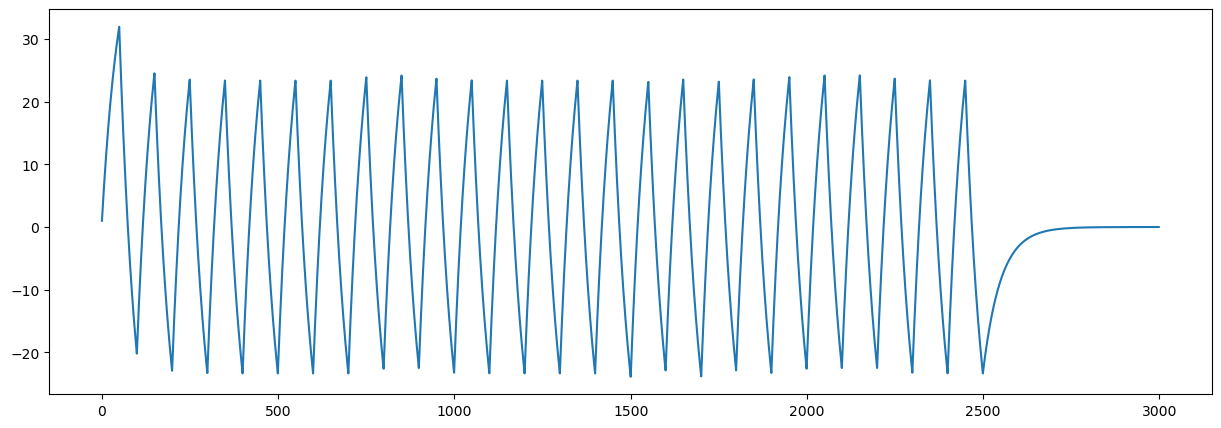

In [40]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)